In [2]:
import numpy as np
import pandas as pd
import os

# Generating tests

In [8]:
seed = 1
# Create the directory if it doesn't exist
os.makedirs(f"point_sets/unif2D", exist_ok=True)

for seed_i in range(25):
    seed = seed_i
    random_points = np.random.rand(200, 2)
    np.random.seed(seed)
    np.savetxt(f"point_sets/unif2D/seed={seed}.csv", random_points, delimiter=",")

In [7]:
seed = 1
# Create the directory if it doesn't exist
os.makedirs(f"point_sets/unif3D", exist_ok=True)

for seed_i in range(25):
    seed = seed_i+1000
    random_points = np.random.rand(100, 3)
    np.random.seed(seed)
    np.savetxt(f"point_sets/unif3D/seed={seed}.csv", random_points, delimiter=",")

In [5]:
seed = 0
# Create the directory if it doesn't exist
os.makedirs(f"point_sets/sphere3D", exist_ok=True)

for seed_i in range(25):
    seed = seed_i+2000
    np.random.seed(seed)

    sphere_points = np.random.rand(150, 3)
    sphere_points /= np.linalg.norm(sphere_points, axis=1)[:, np.newaxis]  # Normalize to lie on the unit sphere
    np.savetxt(f"point_sets/sphere3D/seed={seed}.csv", sphere_points, delimiter=",")

In [4]:
seed = 0

os.makedirs(f"point_sets/unif100D", exist_ok=True)
# Should take rips with max_t of 5 and up to 15 points!
for seed_i in range(25):
    seed = seed_i+3000
    np.random.seed(seed)
    random_points = np.random.rand(20, 100)
    np.savetxt(f"point_sets/unif100D/seed={seed}.csv", random_points, delimiter=",")

# Analyzing results

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import gudhi as gd
from laplacians import compute_boundary_matrices, gudhi_to_dio

def plot_timings(filtration, point_set, seed=0, methods=["new_chains", "petls", "petls_combined", "pinv"], max_t=0.3, x_plot="n_points", log_scale_y=True, log_scale_x=False):
    for method in methods:
        if filtration == "rips":
            csv_file = f"{point_set}_{method}_t={max_t}.csv"
        elif filtration == "alpha":
            csv_file = f"{point_set}_{method}.csv"
        df = pd.read_csv(f"results/timings/{filtration}/{csv_file}", index_col="n_points")

        if x_plot == "n_simplices" or x_plot == "n_timesteps":
            all_points = np.loadtxt(f"point_sets/{point_set}.csv", delimiter=",")
            x_axis = []
            for n in df.index:
                random_points = all_points[:n]
                if filtration == "rips":
                    st = gd.RipsComplex(points=random_points, max_edge_length=max_t).create_simplex_tree(max_dimension=4)
                elif filtration == "alpha":
                    st = gd.AlphaComplex(points=random_points).create_simplex_tree()
                if x_plot == "n_timesteps":
                    boundary_matrices, simplices_at_time, relevant_times = compute_boundary_matrices(gudhi_to_dio(st))
                    x_axis.append(len(relevant_times))
                elif x_plot == "n_simplices":
                    x_axis.append(st.num_simplices())
            df["n_simplices"] = x_axis
            df = df.set_index("n_simplices", drop=True)

        test = df.apply(lambda row: list(row), result_type="reduce", axis=1).explode()

        sns.lineplot(x = test.index, y = test.values, label=method)
        if x_plot == "n_simplices":
            plt.xlabel("Number of simplices")
        elif x_plot == "n_points":
            plt.xlabel("Number of points")
        elif x_plot == "n_timesteps":
            plt.xlabel("Number of timesteps")

        plt.ylabel("Time (seconds)")

        if point_set.startswith("sphere3D"):
            plt.title(f"Timings for points on the unit sphere with {filtration} filtration")
        elif point_set.startswith("unif3D"):
            plt.title(f"Timings for points in the unit cube with {filtration} filtration")

        if log_scale_y:
            plt.yscale("log")
        if log_scale_x:
            plt.xscale("log")
        plt.legend()

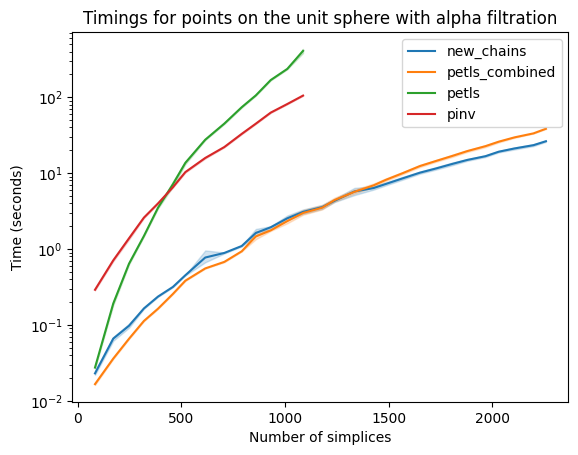

In [93]:
methods = ["new_chains", "petls_combined", "petls", "pinv"]
filtration = "alpha"
max_t = 0.3
point_set = "sphere3D_0"

x_plot = "n_simplices" # or "n_points"

plot_timings(filtration, point_set, methods, max_t, x_plot)

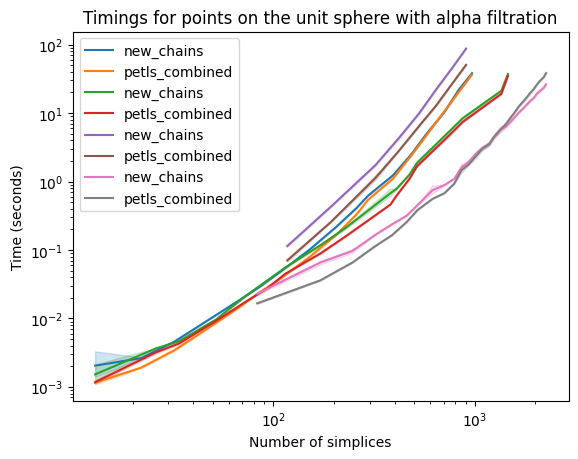

In [94]:
x_plot = "n_simplices" # or "n_simplices"
log_scale_y = True
log_scale_x = True

plot_timings(filtration="rips", point_set="unif3D_0", methods=["new_chains", "petls_combined"], max_t=0.3, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x)
plot_timings(filtration="rips", point_set="unif3D_1", methods=["new_chains", "petls_combined"], max_t=0.3, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x)
plot_timings(filtration="alpha", point_set="unif3D_0", methods=["new_chains", "petls_combined"], max_t=0.3, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x)
plot_timings(filtration="alpha", point_set="sphere3D_0", methods=["new_chains", "petls_combined"], max_t=0.3, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x)